# 03 — Output interpreteren

Deze notebook hoort bij [`docs/output-begrijpen.md`](../docs/output-begrijpen.md#cwf-model-d-cwf).
We:

1. Draaien het CWF-model en lopen de **kolommen** langs
2. Lezen één rij hardop
3. Bekijken hoe je **interval en label** gebruikt in een rapportage
4. Exporteren naar Excel, zoals de opdrachtregel dat doet


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


In [2]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


In [3]:
from studentprognose import run_pipeline_from_dataframes, DataOption
from _helpers import suppress_stdout

PREDICT_YEAR = 2023
PREDICT_WEEK = 12

with suppress_stdout():
    result = run_pipeline_from_dataframes(
        year=PREDICT_YEAR, week=PREDICT_WEEK,
        data_cumulative=data_cumulative_raw,
        data_student_numbers=data_studentcount,
        dataset=DataOption.CWF, save_output=False,
    )
print(f"Output: {result.shape[0]} rijen × {result.shape[1]} kolommen")


Output: 540 rijen × 19 kolommen


## 1. De kolommen

| Groep | Kolommen | Betekenis |
|-------|----------|-----------|
| Sleutel | `Croho groepeernaam`, `Herkomst`, `Examentype`, `Collegejaar`, `Weeknummer` | Waar de rij over gaat |
| Prognose | `Prognose_cwf` | Verwacht aantal eerstejaars |
| Onzekerheid | `cwf_ondergrens`, `cwf_bovengrens` | 95%-interval |
| | `cwf_betrouwbaarheid` | Groen / Oranje / Rood |
| Achtergrond | `cwf_vulgraad` | Hoe ver de cyclus is (0–1) |
| | `cwf_ratiofactor` | Welk deel van de pijplijn naar verwachting instroomt |
| Stand peilweek | `Gewogen vooraanmelders`, `Ongewogen vooraanmelders`, `Inschrijvingen`, … | De aanmeldingen op het peilmoment |
| Realisatie | `Aantal_studenten`, `MAE_Prognose_cwf`, `MAPE_Prognose_cwf` | Alleen gevuld als de instroom al bekend is (terugblik) |

In de Excel-uitvoer van de opdrachtregel staat bovendien `Opleidingsnaam` naast de code.


In [4]:
for kolom in result.columns:
    gevuld = result[kolom].notna().mean()
    print(f"  {kolom:38s} {gevuld:6.0%} gevuld")


  Croho groepeernaam                       100% gevuld
  Faculteit                                100% gevuld
  Examentype                               100% gevuld
  Collegejaar                              100% gevuld
  Herkomst                                 100% gevuld
  Weeknummer                               100% gevuld
  Prognose_cwf                              95% gevuld
  cwf_ondergrens                            93% gevuld
  cwf_bovengrens                            93% gevuld
  cwf_betrouwbaarheid                      100% gevuld
  cwf_vulgraad                             100% gevuld
  cwf_ratiofactor                           64% gevuld
  Aantal_studenten                          95% gevuld
  Gewogen vooraanmelders                    69% gevuld
  Ongewogen vooraanmelders                  69% gevuld
  Aantal aanmelders met 1 aanmelding        69% gevuld
  Inschrijvingen                            69% gevuld
  MAE_Prognose_cwf                          95% gevuld
  MAPE_Pro

## 2. Eén rij hardop gelezen


In [5]:
rij = result[(result["Croho groepeernaam"] == 56604) & (result["Herkomst"] == "NL")
             & (result["Examentype"] == "Bachelor")].iloc[0]

print(f"Opleiding:  {label(rij['Croho groepeernaam'], NAMEN)} · {rij['Herkomst']} · {rij['Examentype']}")
print(f"Peilmoment: week {rij['Weeknummer']} van {rij['Collegejaar']}")
print(f"Pijplijn:   {rij['Gewogen vooraanmelders'] + rij['Inschrijvingen']:.0f} (gewogen vooraanmelders + inschrijvingen)")
print(f"Vulgraad:   {rij['cwf_vulgraad']:.2f} → de cyclus is voor zo'n {rij['cwf_vulgraad']:.0%} gevorderd")
print(f"Ratio:      {rij['cwf_ratiofactor']:.2f} → zo'n {rij['cwf_ratiofactor']:.0%} van de pijplijn stroomt naar verwachting in")
print()
print(f"Prognose:   {rij['Prognose_cwf']:.0f} eerstejaars, "
      f"waarschijnlijk tussen {rij['cwf_ondergrens']:.0f} en {rij['cwf_bovengrens']:.0f}")
print(f"Label:      {rij['cwf_betrouwbaarheid']}")
if pd.notna(rij["Aantal_studenten"]):
    print(f"Realisatie: {rij['Aantal_studenten']:.0f}")


Opleiding:  56604 B Psychologie · NL · Bachelor
Peilmoment: week 12 van 2023
Pijplijn:   1287 (gewogen vooraanmelders + inschrijvingen)
Vulgraad:   0.48 → de cyclus is voor zo'n 48% gevorderd
Ratio:      0.20 → zo'n 20% van de pijplijn stroomt naar verwachting in

Prognose:   240 eerstejaars, waarschijnlijk tussen 198 en 291
Label:      Oranje
Realisatie: 253


## 3. Interval en label in een rapportage

Een prognose zonder bandbreedte wekt de indruk van meer zekerheid dan er is. Twee
vuistregels:

- **Rapporteer het interval**, zeker bij Oranje en Rood. "Tussen 230 en 290" is
  eerlijker dan "260".
- **Tel prognoses op, intervallen niet.** De som van de ondergrenzen is geen
  ondergrens voor het totaal: niet alle opleidingen vallen tegelijk tegen.

Hieronder per label hoe breed de intervallen zijn, als deel van de prognose.


In [6]:
r = result[result["Prognose_cwf"] > 0].copy()
r["breedte_rel"] = (r["cwf_bovengrens"] - r["cwf_ondergrens"]) / r["Prognose_cwf"]
(
    r.groupby("cwf_betrouwbaarheid")
    .agg(combinaties=("Prognose_cwf", "size"),
         mediane_prognose=("Prognose_cwf", "median"),
         mediane_breedte=("breedte_rel", "median"))
    .reindex(["Groen", "Oranje", "Rood"]).dropna(how="all").round(2)
)


,combinaties,mediane_prognose,mediane_breedte
cwf_betrouwbaarheid,,,
Oranje,229.0,74.0,0.60
Rood,273.0,15.0,1.07


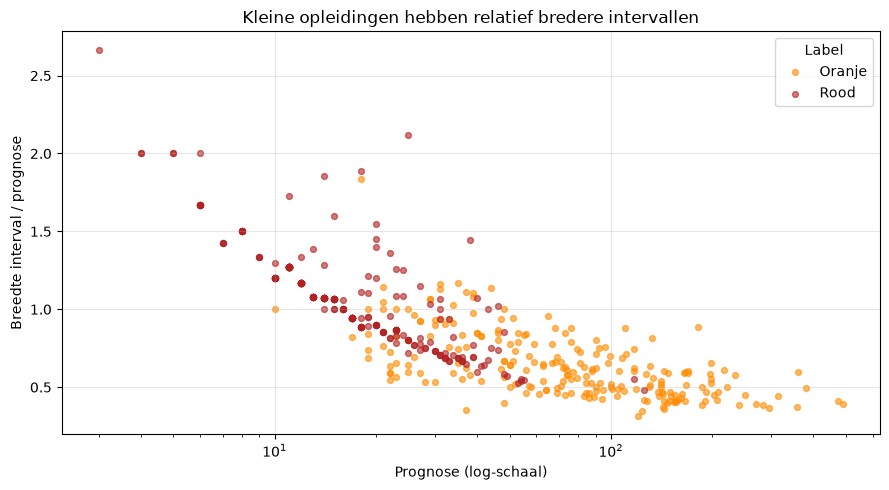

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
kleur = {"Groen": "seagreen", "Oranje": "darkorange", "Rood": "firebrick"}
for lab, g in r.groupby("cwf_betrouwbaarheid"):
    ax.scatter(g["Prognose_cwf"], g["breedte_rel"], s=18, alpha=0.6, color=kleur.get(lab, "gray"), label=lab)
ax.set_xscale("log")
ax.set_xlabel("Prognose (log-schaal)")
ax.set_ylabel("Breedte interval / prognose")
ax.set_title("Kleine opleidingen hebben relatief bredere intervallen")
ax.legend(title="Label")
plt.tight_layout()
plt.show()


Kleine opleidingen schommelen relatief sterker van jaar tot jaar, dus hun interval is
relatief breder. Dat is geen fout van het model maar een eerlijke weergave van de
onzekerheid.

## 4. Exporteren naar Excel

De opdrachtregel schrijft `data/output/output_first-years_cwf.xlsx`. Hier maken we
een eigen export met een overzicht per opleiding (opgeteld over herkomst).


In [8]:
output_path = Path("data/output/notebook_export_cwf.xlsx")
output_path.parent.mkdir(parents=True, exist_ok=True)

export = result.copy()
export.insert(1, "Opleidingsnaam", export["Croho groepeernaam"].map(NAMEN))
per_opleiding = (
    export.groupby(["Croho groepeernaam", "Opleidingsnaam", "Examentype"], as_index=False, dropna=False)
    [["Prognose_cwf", "Aantal_studenten"]].sum(min_count=1)
)
with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    export.to_excel(writer, sheet_name="per_herkomst", index=False)
    per_opleiding.to_excel(writer, sheet_name="per_opleiding", index=False)

print(f"✅ Geschreven: {output_path} ({output_path.stat().st_size / 1024:.0f} KB)")


✅ Geschreven: data/output/notebook_export_cwf.xlsx (75 KB)


## 5. Dashboard

Met `--dashboard` maakt de opdrachtregel er een interactief HTML-dashboard bij, met
prognose, interval en label per opleiding:

```bash
studentprognose -d cwf -y 2025 -w 12 --dashboard
```

Zie [Output begrijpen](../docs/output-begrijpen.md#interactief-dashboard).

## 6. Beslisregels

**Meer vertrouwen:**
- Label Groen of Oranje
- Smal interval in verhouding tot de prognose
- Later in de cyclus (hogere vulgraad)

**Minder vertrouwen:**
- Label Rood
- Nieuwe opleiding of weinig historie
- Numerus fixus (de capaciteit bepaalt de instroom, niet de aanmeldingen)
- Een jaar met een beleidswijziging of een ander aanmeldmoment
